# INTI-3K · Notebook Reproducible Oficial (`submission_notebook.ipynb`)

**Hackathon IA PUCP 2026 (DSC PUCP × IA-PUCP) · Equipo PASSWORD**

Este notebook **100% autocontenido** reproduce de principio a fin el entrenamiento de nuestro modelo único unificado **`EnsembleDownscaler`** (3 familias arquitectónicas complementarias guiadas por física andina) utilizando **exclusivamente la data oficial** de la competencia (`train.npz`, `test.npz`, `static.npz`):

1. **Validación Temporal Estricta (`val = ttr >= '2024061600'`)**: Últimas 2 semanas de junio de 2024 (cero split aleatorio, cero data leakage) usando el **Skill Score oficial** sobre la climatología por hora UTC.
2. **Ingeniería Física Andina**:
   - Ventanas centradas del GFS `[t-6, t-3, t-1, t, t+1, t+3, t+6]` + promedio móvil de 24h (captura desfases horarios y régimen estacional seco/húmedo).
   - Punto de Rocío ($T_d$, fórmula de Magnus), prior térmico por gradiente de elevación (`-6.5 °C/km`), forzamiento orográfico ($\vec{V}_{\text{GFS}} \cdot \nabla \text{DEM}$) y 10 canales topográficos derivados del `DEM`.
3. **3 Familias Arquitectónicas Complementarias**:
   - **`PhysicsUNet`** (pirámide multi-escala `3×3` con atención *Squeeze-and-Excitation*): especialista en viento local.
   - **`PhysicsConvNeXt`** (kernels `7×7` dilatados a resolución completa `70×35` sin compresión): especialista en temperatura y relieve.
   - **`PhysicsFNO`** (Fourier Neural Operator 2D): especialista en campos atmosféricos globales y humedad relativa (`RH`).
4. **Empaquetado Único & Entregables**: Une las 3 ramas en un solo `nn.Module` (`EnsembleDownscaler`), exporta los pesos limpios en `models/modelo.pt` (`~30.7 MB`) y `models/norm_stats.npz`, genera `submission.csv` (`646,800` filas, `RH` en `[0, 100]`) y lo verifica contra `sample_submission.csv`.

> Compatible con **Local (GPU CUDA)**, **Google Colab (T4)** y **Kaggle Notebooks (GPU T4)**.


In [1]:
import copy
import glob
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

DEFAULT_SEED = 42

def seed_everything(seed: int = DEFAULT_SEED) -> int:
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    return seed

seed_everything(DEFAULT_SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo activo: {device.upper()} | PyTorch: {torch.__version__}")

def find(name: str) -> str:
    hits = (
        glob.glob(f"/kaggle/input/**/{name}", recursive=True)
        + glob.glob(f"../data/**/{name}", recursive=True)
        + glob.glob(f"data/**/{name}", recursive=True)
        + glob.glob(f"**/{name}", recursive=True)
    )
    assert hits, f"No encuentro {name}. Descarga la data oficial en data/."
    return hits[0]

ROOT_DIR = Path("..").resolve() if (Path("../data").is_dir() or Path("../models").is_dir()) else Path(".").resolve()
MODELS_DIR = ROOT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

tr = np.load(find("train.npz"))
te = np.load(find("test.npz"))
st = dict(np.load(find("static.npz")))

Xtr, Ytr, ttr = tr["X"], tr["Y"], tr["times"].astype(str)
Xte, tte = te["X"], te["times"].astype(str)
dem = st["dem"].astype(np.float32)

VARS = ["RH", "T", "U", "V"]
UNITS = ["%", "K", "m/s", "m/s"]

print(f"Train X: {Xtr.shape} | Y: {Ytr.shape} | Rango: {ttr[0]} -> {ttr[-1]}")
print(f"Test  X: {Xte.shape} | Rango: {tte[0]} -> {tte[-1]}")
print(f"DEM: {dem.shape} | Elevación: {dem.min():.0f} m - {dem.max():.0f} m")


Dispositivo activo: CUDA | PyTorch: 2.14.1+cu126


Train X: (2935, 17, 13, 4) | Y: (2935, 70, 35, 4) | Rango: 2024021800 -> 2024063023
Test  X: (792, 17, 13, 4) | Rango: 2024070200 -> 2024080423
DEM: (70, 35) | Elevación: 115 m - 5782 m


In [2]:
def extract_hour_utc(t: np.ndarray) -> np.ndarray:
    return np.array([int(str(k)[-2:]) for k in t], dtype=np.int64)

def compute_climatology(Y: np.ndarray, t: np.ndarray) -> np.ndarray:
    h = extract_hour_utc(t)
    return np.stack([Y[h == k].mean(0) for k in range(24)]).astype(np.float32)

val_mask = ttr >= "2024061600"
trn_mask = ~val_mask

h_tr = extract_hour_utc(ttr)
h_te = extract_hour_utc(tte)

clim_trn = compute_climatology(Ytr[trn_mask], ttr[trn_mask])
clim_rmse_val = np.sqrt(((clim_trn[h_tr[val_mask]] - Ytr[val_mask]) ** 2).mean(axis=(0, 1, 2)))
clim_rmse_trn = np.sqrt(((clim_trn[h_tr[trn_mask]] - Ytr[trn_mask]) ** 2).mean(axis=(0, 1, 2))).astype(np.float32)

def evaluate_skill_score(pred: np.ndarray, true: np.ndarray):
    rmse = np.sqrt(((pred - true) ** 2).mean(axis=(0, 1, 2)))
    rel_skill = 1.0 - (rmse / clim_rmse_val)
    total_skill = float(rel_skill.mean())
    rmse_dict = {k: round(float(v), 4) for k, v in zip(VARS, rmse)}
    skill_dict = {k: round(float(v), 4) for k, v in zip(VARS, rel_skill)}
    return total_skill, rmse_dict, skill_dict

base_sc, base_rmse, _ = evaluate_skill_score(clim_trn[h_tr[val_mask]], Ytr[val_mask])
print(f"Split Temporal -> Train: {trn_mask.sum()} h | Val (16-30 jun): {val_mask.sum()} h")
print(f"Baseline Climatología -> Skill Score: {base_sc:.4f} | RMSE: {base_rmse}")


Split Temporal -> Train: 2599 h | Val (16-30 jun): 336 h
Baseline Climatología -> Skill Score: 0.0000 | RMSE: {'RH': 17.1766, 'T': 2.0097, 'U': 2.2607, 'V': 1.9455}


In [3]:
CENTERED_LAGS = (-6, -3, -1, 0, 1, 3, 6)

def smooth_2d(a: np.ndarray, k: int = 9) -> np.ndarray:
    p = k // 2
    ap = np.pad(a, p, mode="edge")
    out = np.zeros_like(a, dtype=np.float32)
    for di in range(k):
        for dj in range(k):
            out += ap[di : di + a.shape[0], dj : dj + a.shape[1]]
    return out / (k * k)

def build_topographic_features(dem_arr: np.ndarray, wrf_lats: np.ndarray, wrf_lons: np.ndarray) -> np.ndarray:
    dem_f = dem_arr.astype(np.float32)
    dem_norm = (dem_f - dem_f.mean()) / (dem_f.std() + 1e-6)
    dy, dx = np.gradient(dem_f)
    dx_norm = (dx - dx.mean()) / (dx.std() + 1e-6)
    dy_norm = (dy - dy.mean()) / (dy.std() + 1e-6)
    slope = np.sqrt(dx**2 + dy**2)
    slope_norm = (slope - slope.mean()) / (slope.std() + 1e-6)
    aspect = np.arctan2(dy, dx)
    sin_aspect = np.sin(aspect).astype(np.float32)
    cos_aspect = np.cos(aspect).astype(np.float32)
    tpi_local = dem_f - smooth_2d(dem_f, k=3)
    tpi_local_norm = (tpi_local - tpi_local.mean()) / (tpi_local.std() + 1e-6)
    tpi_meso = dem_f - smooth_2d(dem_f, k=9)
    tpi_meso_norm = (tpi_meso - tpi_meso.mean()) / (tpi_meso.std() + 1e-6)
    LAT, LON = np.meshgrid(wrf_lats, wrf_lons, indexing="ij")
    lat_norm = ((LAT - LAT.mean()) / (LAT.std() + 1e-6)).astype(np.float32)
    lon_norm = ((LON - LON.mean()) / (LON.std() + 1e-6)).astype(np.float32)
    return np.stack([
        dem_norm, dy_norm, dx_norm, slope_norm,
        sin_aspect, cos_aspect, tpi_local_norm, tpi_meso_norm,
        lat_norm, lon_norm,
    ], axis=0).astype(np.float32)

def build_sampling_grid(st_dict, dev: str) -> torch.Tensor:
    glat, glon = st_dict["gfs_lats"], st_dict["gfs_lons"]
    wlat, wlon = st_dict["wrf_lats"], st_dict["wrf_lons"]
    LAT, LON = np.meshgrid(wlat, wlon, indexing="ij")
    gy = (LAT - glat[0]) / (glat[-1] - glat[0]) * 2 - 1
    gx = (LON - glon[0]) / (glon[-1] - glon[0]) * 2 - 1
    grid = np.stack([gx, gy], axis=-1)[None].astype(np.float32)
    return torch.tensor(grid, dtype=torch.float32, device=dev)

def compute_dewpoint_c(T_k: np.ndarray, RH_pct: np.ndarray) -> np.ndarray:
    T_c = T_k - 273.15
    rh = np.clip(RH_pct, 1.0, 100.0) / 100.0
    a, b = 17.625, 243.04
    gamma = np.log(rh) + (a * T_c) / (b + T_c)
    return ((b * gamma) / (a - gamma)).astype(np.float32)

def build_centered_windows_and_daily_mean(X: np.ndarray, t: np.ndarray, lags=CENTERED_LAGS):
    ts = pd.to_datetime(t.astype(str), format="%Y%m%d%H")
    ts_ns = ts.values.astype("datetime64[h]").astype(np.int64)
    pos = {int(h): i for i, h in enumerate(ts_ns)}
    N = len(X)
    W = np.empty((N, len(lags)) + X.shape[1:], dtype=np.float32)
    M24 = np.empty_like(X, dtype=np.float32)
    for i, cur_h in enumerate(ts_ns):
        for j, lag in enumerate(lags):
            target_h = int(cur_h + lag)
            idx = pos.get(target_h, None)
            if idx is None:
                for delta in (1, -1, 2, -2, 3, -3):
                    idx = pos.get(target_h + delta, None)
                    if idx is not None:
                        break
            W[i, j] = X[idx] if idx is not None else X[i]
        win_idxs = [pos[int(cur_h + d)] for d in range(-12, 13) if int(cur_h + d) in pos]
        M24[i] = X[win_idxs].mean(axis=0) if win_idxs else X[i]
    return W, M24

t0 = time.time()
Wtr, M24_tr = build_centered_windows_and_daily_mean(Xtr, ttr)
Wte, M24_te = build_centered_windows_and_daily_mean(Xte, tte)
Td_tr = compute_dewpoint_c(Xtr[..., 1], Xtr[..., 0])[:, None, :, :]
Td_te = compute_dewpoint_c(Xte[..., 1], Xte[..., 0])[:, None, :, :]

# Estadísticas de normalización calculadas SOLO con el subconjunto de entrenamiento
mu_x = Xtr[trn_mask].mean(axis=(0, 1, 2)).astype(np.float32)
sd_x = Xtr[trn_mask].std(axis=(0, 1, 2)).astype(np.float32)
mu_td = float(Td_tr[trn_mask].mean())
sd_td = float(Td_tr[trn_mask].std() + 1e-6)
anom_sd = (Ytr[trn_mask] - clim_trn[h_tr[trn_mask]]).std(axis=(0, 1, 2)).astype(np.float32)

Wtr_n = ((Wtr - mu_x) / sd_x).astype(np.float32)
M24_tr_n = ((M24_tr - mu_x) / sd_x).astype(np.float32)
Td_tr_n = ((Td_tr - mu_td) / sd_td).astype(np.float32)

Wte_n = ((Wte - mu_x) / sd_x).astype(np.float32)
M24_te_n = ((M24_te - mu_x) / sd_x).astype(np.float32)
Td_te_n = ((Td_te - mu_td) / sd_td).astype(np.float32)

months_tr = pd.to_datetime(ttr, format="%Y%m%d%H").month.values
month_w_map = {2: 0.55, 3: 0.80, 4: 0.90, 5: 1.15, 6: 1.40}
sample_weights = np.array([month_w_map.get(int(m), 1.0) for m in months_tr], dtype=np.float32)
sample_weights[trn_mask] /= sample_weights[trn_mask].mean()

grid_t = build_sampling_grid(st, device)
topo_np = build_topographic_features(dem, st["wrf_lats"], st["wrf_lons"])
topo_t = torch.tensor(topo_np, dtype=torch.float32, device=device)
dem_smooth = smooth_2d(dem, k=9)
lapse_delta = (-0.0065 * (dem - dem_smooth)) / float(sd_x[1])
lapse_delta_t = torch.tensor(lapse_delta, dtype=torch.float32, device=device)

CLIM_T = torch.tensor(clim_trn, dtype=torch.float32, device=device)
ASD_T = torch.tensor(anom_sd, dtype=torch.float32, device=device)
CLIM_RMSE_TRN_T = torch.tensor(clim_rmse_trn, dtype=torch.float32, device=device)

print(f"Preprocesamiento físico completado en {time.time()-t0:.1f}s | Wtr_n: {Wtr_n.shape}")


Preprocesamiento físico completado en 2.2s | Wtr_n: (2935, 7, 17, 13, 4)


In [4]:
class SEBlock(nn.Module):
    def __init__(self, channels: int, reduction: int = 4):
        super().__init__()
        mid = max(channels // reduction, 8)
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(channels, mid), nn.GELU(),
            nn.Linear(mid, channels), nn.Sigmoid(),
        )
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * self.fc(x).unsqueeze(-1).unsqueeze(-1)

class CompactResBlock(nn.Module):
    def __init__(self, channels: int, dropout: float = 0.10):
        super().__init__()
        groups = 8 if channels % 8 == 0 else 4
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.GroupNorm(groups, channels), nn.GELU(),
            nn.Dropout2d(dropout) if dropout > 0 else nn.Identity(),
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.GroupNorm(groups, channels),
        )
        self.se = SEBlock(channels)
        self.act = nn.GELU()
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.act(x + self.se(self.block(x)))

def _build_shared_inputs(w_norm, m24_norm, td_norm, h, grid, topo, lapse_delta, gfs_encoder, learned_static):
    B = w_norm.shape[0]
    xt, xm3, xp3 = w_norm[:, 3], w_norm[:, 1], w_norm[:, 5]
    wspd = torch.stack([
        torch.sqrt(w_norm[:, idx, :, :, 2]**2 + w_norm[:, idx, :, :, 3]**2 + 1e-6)
        for idx in (1, 3, 5)
    ], dim=1)
    d_prev = (xt - xm3).permute(0, 3, 1, 2)
    d_next = (xp3 - xt).permute(0, 3, 1, 2)
    d_diurnal = (xt - m24_norm).permute(0, 3, 1, 2)
    w_flat = w_norm.permute(0, 1, 4, 2, 3).reshape(B, 28, 17, 13)
    m24_flat = m24_norm.permute(0, 3, 1, 2)
    ang = 2.0 * np.pi * h / 24.0
    h_vec = torch.stack([torch.sin(ang), torch.cos(ang)], dim=1)
    hh_low = h_vec[..., None, None].expand(B, 2, 17, 13)
    gfs_in = torch.cat([w_flat, m24_flat, td_norm, wspd, d_prev, d_next, d_diurnal, hh_low], dim=1)
    f_low = gfs_encoder(gfs_in)
    grid_b = grid.expand(B, -1, -1, -1)
    f_up = F.grid_sample(f_low, grid_b, mode="bilinear", align_corners=True)
    raw_cat = torch.cat([xt.permute(0, 3, 1, 2), m24_flat, td_norm], dim=1)
    raw_up = F.grid_sample(raw_cat, grid_b, mode="bilinear", align_corners=True)
    topo_b = topo.expand(B, -1, -1, -1)
    u_up, v_up = raw_up[:, 2:3], raw_up[:, 3:4]
    dy_n, dx_n = topo_b[:, 1:2], topo_b[:, 2:3]
    oro_feats = torch.cat([u_up * dx_n + v_up * dy_n, u_up * dy_n - v_up * dx_n], dim=1)
    t_prior = raw_up[:, 1:2] + lapse_delta.expand(B, -1, -1, -1)
    static_b = learned_static.expand(B, -1, -1, -1)
    hh_high = h_vec[..., None, None].expand(B, 2, 70, 35)
    fused = torch.cat([f_up, raw_up, t_prior, oro_feats, topo_b, static_b, hh_high], dim=1)
    return fused, topo_b, oro_feats

class PhysicsUNet(nn.Module):
    def __init__(self, grid, topo_features, lapse_delta_norm, w: int = 64, dropout: float = 0.12):
        super().__init__()
        self.register_buffer("grid", grid)
        self.register_buffer("topo", topo_features[None])
        self.register_buffer("lapse_delta", lapse_delta_norm[None, None])
        self.gfs_enc = nn.Sequential(
            nn.Conv2d(50, w, 3, padding=1, bias=False), nn.GroupNorm(8, w), nn.GELU(),
            CompactResBlock(w, dropout=dropout * 0.5), CompactResBlock(w, dropout=dropout * 0.5),
        )
        self.learned_static = nn.Parameter(torch.zeros(1, 12, 70, 35))
        nn.init.normal_(self.learned_static, mean=0.0, std=0.01)
        fused_ch = w + 8 + 1 + 1 + 2 + 10 + 12 + 2
        self.enc1 = nn.Sequential(nn.Conv2d(fused_ch, w, 3, padding=1, bias=False), nn.GroupNorm(8, w), nn.GELU(), CompactResBlock(w, dropout))
        self.enc2 = nn.Sequential(nn.Conv2d(w, w * 2, 3, stride=2, padding=1, bias=False), nn.GroupNorm(8, w * 2), nn.GELU(), CompactResBlock(w * 2, dropout))
        self.enc3 = nn.Sequential(nn.Conv2d(w * 2, w * 2, 3, stride=2, padding=1, bias=False), nn.GroupNorm(8, w * 2), nn.GELU(), CompactResBlock(w * 2, dropout * 1.25))
        self.dec2 = nn.Sequential(nn.Conv2d(w * 4, w * 2, 3, padding=1, bias=False), nn.GroupNorm(8, w * 2), nn.GELU(), CompactResBlock(w * 2, dropout))
        self.dec1 = nn.Sequential(nn.Conv2d(w * 3, w, 3, padding=1, bias=False), nn.GroupNorm(8, w), nn.GELU(), CompactResBlock(w, dropout * 0.5))
        head_in = w + 12
        self.head_thermo = nn.Sequential(nn.Conv2d(head_in, w // 2, 3, padding=1), nn.GELU(), nn.Conv2d(w // 2, 2, 1))
        self.head_wind = nn.Sequential(nn.Conv2d(head_in, w // 2, 3, padding=1), nn.GELU(), nn.Conv2d(w // 2, 2, 1))

    def forward(self, w_norm, m24_norm, td_norm, h):
        fused, topo_b, oro_feats = _build_shared_inputs(w_norm, m24_norm, td_norm, h, self.grid, self.topo, self.lapse_delta, self.gfs_enc, self.learned_static)
        s1 = self.enc1(fused)
        s2 = self.enc2(s1)
        s3 = self.enc3(s2)
        u2 = F.interpolate(s3, size=s2.shape[-2:], mode="bilinear", align_corners=True)
        d2 = self.dec2(torch.cat([s2, u2], dim=1))
        u1 = F.interpolate(d2, size=s1.shape[-2:], mode="bilinear", align_corners=True)
        d1 = self.dec1(torch.cat([s1, u1], dim=1))
        head_in = torch.cat([d1, topo_b, oro_feats], dim=1)
        return torch.cat([self.head_thermo(head_in), self.head_wind(head_in)], dim=1).permute(0, 2, 3, 1)

class ConvNeXtBlock2D(nn.Module):
    def __init__(self, dim: int, kernel_size: int = 7, dilation: int = 1, expand: int = 3, dropout: float = 0.12):
        super().__init__()
        padding = (kernel_size - 1) * dilation // 2
        self.dwconv = nn.Conv2d(dim, dim, kernel_size=kernel_size, padding=padding, dilation=dilation, groups=dim)
        self.norm = nn.GroupNorm(1, dim)
        self.pw1 = nn.Conv2d(dim, dim * expand, kernel_size=1)
        self.act = nn.GELU()
        self.drop = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()
        self.pw2 = nn.Conv2d(dim * expand, dim, kernel_size=1)
        self.gamma = nn.Parameter(1e-3 * torch.ones(1, dim, 1, 1))
    def forward(self, x):
        return x + self.gamma * self.pw2(self.drop(self.act(self.pw1(self.norm(self.dwconv(x))))))

class PhysicsConvNeXt(nn.Module):
    def __init__(self, grid, topo_features, lapse_delta_norm, w: int = 80, dropout: float = 0.15):
        super().__init__()
        self.register_buffer("grid", grid)
        self.register_buffer("topo", topo_features[None])
        self.register_buffer("lapse_delta", lapse_delta_norm[None, None])
        self.gfs_stem = nn.Sequential(
            nn.Conv2d(50, w, 3, padding=1), nn.GroupNorm(1, w), nn.GELU(),
            ConvNeXtBlock2D(w, 5, 1, 2, dropout * 0.5), ConvNeXtBlock2D(w, 5, 1, 2, dropout * 0.5),
        )
        self.learned_static = nn.Parameter(torch.zeros(1, 12, 70, 35))
        nn.init.normal_(self.learned_static, mean=0.0, std=0.01)
        fused_ch = w + 9 + 1 + 2 + 10 + 12 + 2
        self.highres_stem = nn.Sequential(nn.Conv2d(fused_ch, w, 1), nn.GroupNorm(1, w), nn.GELU())
        self.blocks = nn.Sequential(
            ConvNeXtBlock2D(w, 7, 1, 3, dropout), ConvNeXtBlock2D(w, 7, 2, 3, dropout),
            ConvNeXtBlock2D(w, 7, 1, 3, dropout), ConvNeXtBlock2D(w, 7, 3, 3, dropout),
            ConvNeXtBlock2D(w, 7, 1, 3, dropout), ConvNeXtBlock2D(w, 5, 1, 2, dropout * 0.5),
        )
        head_in = w + 12
        self.head_thermo = nn.Sequential(nn.Conv2d(head_in, w // 2, 3, padding=1), nn.GELU(), nn.Conv2d(w // 2, 2, 1))
        self.head_wind = nn.Sequential(nn.Conv2d(head_in, w // 2, 3, padding=1), nn.GELU(), nn.Conv2d(w // 2, 2, 1))

    def forward(self, w_norm, m24_norm, td_norm, h):
        fused, topo_b, oro_feats = _build_shared_inputs(w_norm, m24_norm, td_norm, h, self.grid, self.topo, self.lapse_delta, self.gfs_stem, self.learned_static)
        feat = self.blocks(self.highres_stem(fused))
        head_in = torch.cat([feat, topo_b, oro_feats], dim=1)
        return torch.cat([self.head_thermo(head_in), self.head_wind(head_in)], dim=1).permute(0, 2, 3, 1)

class SpectralConv2d(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, modes1: int = 16, modes2: int = 10):
        super().__init__()
        self.out_channels, self.modes1, self.modes2 = out_channels, modes1, modes2
        scale = 1.0 / (in_channels * out_channels)
        self.w1_r = nn.Parameter(scale * torch.randn(in_channels, out_channels, modes1, modes2))
        self.w1_i = nn.Parameter(scale * torch.randn(in_channels, out_channels, modes1, modes2))
        self.w2_r = nn.Parameter(scale * torch.randn(in_channels, out_channels, modes1, modes2))
        self.w2_i = nn.Parameter(scale * torch.randn(in_channels, out_channels, modes1, modes2))
    @staticmethod
    def _compl_mul2d(xr, xi, wr, wi):
        return torch.complex(
            torch.einsum("bixy,ioxy->boxy", xr, wr) - torch.einsum("bixy,ioxy->boxy", xi, wi),
            torch.einsum("bixy,ioxy->boxy", xr, wi) + torch.einsum("bixy,ioxy->boxy", xi, wr),
        )
    def forward(self, x):
        B, C, H, W = x.shape
        x_ft = torch.fft.rfft2(x, norm="ortho")
        out_ft = torch.zeros(B, self.out_channels, H, W // 2 + 1, dtype=torch.cfloat, device=x.device)
        m1, m2 = min(self.modes1, H // 2), min(self.modes2, W // 2 + 1)
        x1, x2 = x_ft[:, :, :m1, :m2], x_ft[:, :, -m1:, :m2]
        out_ft[:, :, :m1, :m2] = self._compl_mul2d(x1.real, x1.imag, self.w1_r[:, :, :m1, :m2], self.w1_i[:, :, :m1, :m2])
        out_ft[:, :, -m1:, :m2] = self._compl_mul2d(x2.real, x2.imag, self.w2_r[:, :, :m1, :m2], self.w2_i[:, :, :m1, :m2])
        return torch.fft.irfft2(out_ft, s=(H, W), norm="ortho")

class FNOBlock2D(nn.Module):
    def __init__(self, dim: int, modes1: int = 16, modes2: int = 10, dropout: float = 0.12):
        super().__init__()
        self.spectral = SpectralConv2d(dim, dim, modes1=modes1, modes2=modes2)
        self.local_conv = nn.Conv2d(dim, dim, 3, padding=1, groups=dim)
        self.pw = nn.Conv2d(dim, dim, 1)
        self.norm = nn.GroupNorm(8, dim)
        self.act = nn.GELU()
        self.drop = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()
    def forward(self, x):
        return x + self.drop(self.act(self.norm(self.spectral(x) + self.pw(self.local_conv(x)))))

class PhysicsFNO(nn.Module):
    def __init__(self, grid, topo_features, lapse_delta_norm, w: int = 48, dropout: float = 0.12):
        super().__init__()
        self.register_buffer("grid", grid)
        self.register_buffer("topo", topo_features[None])
        self.register_buffer("lapse_delta", lapse_delta_norm[None, None])
        self.gfs_stem = nn.Sequential(
            nn.Conv2d(50, w, 3, padding=1, bias=False), nn.GroupNorm(8, w), nn.GELU(),
            FNOBlock2D(w, modes1=6, modes2=5, dropout=dropout * 0.5),
        )
        self.learned_static = nn.Parameter(torch.zeros(1, 12, 70, 35))
        nn.init.normal_(self.learned_static, mean=0.0, std=0.01)
        fused_ch = w + 9 + 1 + 2 + 10 + 12 + 2
        self.lift = nn.Sequential(nn.Conv2d(fused_ch, w, 1, bias=False), nn.GroupNorm(8, w), nn.GELU())
        self.fno_layers = nn.Sequential(
            FNOBlock2D(w, 16, 10, dropout), FNOBlock2D(w, 16, 10, dropout),
            FNOBlock2D(w, 12, 8, dropout), FNOBlock2D(w, 12, 8, dropout * 0.5),
        )
        head_in = w + 12
        self.head_thermo = nn.Sequential(nn.Conv2d(head_in, w, 3, padding=1), nn.GELU(), nn.Conv2d(w, 2, 1))
        self.head_wind = nn.Sequential(nn.Conv2d(head_in, w, 3, padding=1), nn.GELU(), nn.Conv2d(w, 2, 1))

    def forward(self, w_norm, m24_norm, td_norm, h):
        fused, topo_b, oro_feats = _build_shared_inputs(w_norm, m24_norm, td_norm, h, self.grid, self.topo, self.lapse_delta, self.gfs_stem, self.learned_static)
        feat = self.fno_layers(self.lift(fused))
        head_in = torch.cat([feat, topo_b, oro_feats], dim=1)
        return torch.cat([self.head_thermo(head_in), self.head_wind(head_in)], dim=1).permute(0, 2, 3, 1)

class EnsembleDownscaler(nn.Module):
    def __init__(self, grid, topo_features, lapse_delta_norm, blend_weights, unet_w=64, convnext_w=80, fno_w=48):
        super().__init__()
        self.unet = PhysicsUNet(grid, topo_features, lapse_delta_norm, w=unet_w, dropout=0.0)
        self.convnext = PhysicsConvNeXt(grid, topo_features, lapse_delta_norm, w=convnext_w, dropout=0.0)
        self.fno = PhysicsFNO(grid, topo_features, lapse_delta_norm, w=fno_w, dropout=0.0)
        self.register_buffer("blend_weights", torch.tensor(blend_weights, dtype=torch.float32))

    def forward(self, w_norm, m24_norm, td_norm, h):
        out_u = self.unet(w_norm, m24_norm, td_norm, h)
        out_c = self.convnext(w_norm, m24_norm, td_norm, h)
        out_f = self.fno(w_norm, m24_norm, td_norm, h)
        bw = self.blend_weights
        return bw[0].view(1, 1, 1, 4) * out_u + bw[1].view(1, 1, 1, 4) * out_c + bw[2].view(1, 1, 1, 4) * out_f


In [5]:
def update_ema(ema_model, model, decay=0.992):
    with torch.no_grad():
        for pe, p in zip(ema_model.parameters(), model.parameters()):
            pe.data.mul_(decay).add_(p.data, alpha=1.0 - decay)

def predict_with_model(net, Wn, Mn, Tn, h_all, bs=128):
    net.eval()
    preds = []
    with torch.no_grad():
        for s in range(0, len(Wn), bs):
            xb = torch.tensor(Wn[s:s+bs], dtype=torch.float32, device=device)
            mb = torch.tensor(Mn[s:s+bs], dtype=torch.float32, device=device)
            tb = torch.tensor(Tn[s:s+bs], dtype=torch.float32, device=device)
            hb = torch.tensor(h_all[s:s+bs], dtype=torch.long, device=device)
            pred_anom = net(xb, mb, tb, hb.float())
            y_hat = (CLIM_T[hb] + pred_anom * ASD_T).cpu().numpy()
            y_hat[..., 0] = np.clip(y_hat[..., 0], 0.0, 100.0)
            preds.append(y_hat)
    return np.concatenate(preds, axis=0)

def train_member(name, model, epochs=35, batch_size=32, lr=1.5e-3, weight_decay=1e-2, noise_std=0.04, seed=42):
    seed_everything(seed)
    model = model.to(device)
    ema_model = copy.deepcopy(model).eval()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    itr = np.where(trn_mask)[0]
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, total_steps=epochs * int(np.ceil(len(itr) / batch_size)), pct_start=0.15
    )

    best_sc, best_state, best_src = -1e9, None, "LIVE"
    t_start = time.time()
    for ep in range(epochs):
        model.train()
        np.random.shuffle(itr)
        for s in range(0, len(itr), batch_size):
            b = itr[s:s+batch_size]
            xb = torch.tensor(Wtr_n[b], dtype=torch.float32, device=device)
            mb = torch.tensor(M24_tr_n[b], dtype=torch.float32, device=device)
            tb = torch.tensor(Td_tr_n[b], dtype=torch.float32, device=device)
            hb = torch.tensor(h_tr[b], dtype=torch.long, device=device)
            wb = torch.tensor(sample_weights[b], dtype=torch.float32, device=device)
            yb = torch.tensor(Ytr[b], dtype=torch.float32, device=device)
            if noise_std > 0:
                xb = xb + torch.randn_like(xb) * noise_std
                mb = mb + torch.randn_like(mb) * (noise_std * 0.5)
            pred_anom = model(xb, mb, tb, hb.float())
            y_pred = CLIM_T[hb] + pred_anom * ASD_T
            err_sq = ((y_pred - yb) ** 2).mean(dim=(1, 2))
            w_mse = (err_sq * wb[:, None]).sum(dim=0) / (wb.sum() + 1e-8)
            skill_loss = (torch.sqrt(w_mse + 1e-6) / CLIM_RMSE_TRN_T).mean()
            optimizer.zero_grad()
            skill_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            optimizer.step()
            scheduler.step()
            update_ema(ema_model, model, decay=0.992)

        vp_live = predict_with_model(model, Wtr_n[val_mask], M24_tr_n[val_mask], Td_tr_n[val_mask], h_tr[val_mask])
        sc_live, _, _ = evaluate_skill_score(vp_live, Ytr[val_mask])
        sc_ema = -1e9
        if ep >= 5:
            vp_ema = predict_with_model(ema_model, Wtr_n[val_mask], M24_tr_n[val_mask], Td_tr_n[val_mask], h_tr[val_mask])
            sc_ema, _, _ = evaluate_skill_score(vp_ema, Ytr[val_mask])
        sc_ep = max(sc_live, sc_ema)
        if sc_ep > best_sc:
            best_sc = sc_ep
            best_src = "EMA" if sc_ema >= sc_live else "LIVE"
            cand = ema_model if sc_ema >= sc_live else model
            best_state = {k: v.detach().cpu().clone() for k, v in cand.state_dict().items()}
        if (ep + 1) % 7 == 0 or ep == epochs - 1:
            print(f"[{name}] Época {ep+1:02d}/{epochs} · Best Val Skill: {best_sc:.4f} ({best_src})")

    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    val_oof = predict_with_model(model, Wtr_n[val_mask], M24_tr_n[val_mask], Td_tr_n[val_mask], h_tr[val_mask])
    sc_fin, rmse_fin, skill_fin = evaluate_skill_score(val_oof, Ytr[val_mask])
    print(f"--> {name} finalizado en {time.time()-t_start:.1f}s | Skill: {sc_fin:.4f} | Por var: {skill_fin}\n")
    return best_state, val_oof, sc_fin

state_unet, oof_unet, sc_unet = train_member(
    "PhysicsUNet",
    PhysicsUNet(grid_t, topo_t, lapse_delta_t, w=64, dropout=0.12),
    epochs=35, lr=1.5e-3, weight_decay=1e-2, noise_std=0.04, seed=42,
)
state_conv, oof_conv, sc_conv = train_member(
    "PhysicsConvNeXt",
    PhysicsConvNeXt(grid_t, topo_t, lapse_delta_t, w=80, dropout=0.15),
    epochs=35, lr=2.0e-3, weight_decay=1.5e-2, noise_std=0.05, seed=102,
)
state_fno, oof_fno, sc_fno = train_member(
    "PhysicsFNO",
    PhysicsFNO(grid_t, topo_t, lapse_delta_t, w=48, dropout=0.12),
    epochs=35, lr=2.0e-3, weight_decay=2.0e-2, noise_std=0.05, seed=203,
)


[PhysicsUNet] Época 07/35 · Best Val Skill: 0.3175 (EMA)


[PhysicsUNet] Época 14/35 · Best Val Skill: 0.3597 (EMA)


[PhysicsUNet] Época 21/35 · Best Val Skill: 0.3626 (EMA)


[PhysicsUNet] Época 28/35 · Best Val Skill: 0.3626 (EMA)


[PhysicsUNet] Época 35/35 · Best Val Skill: 0.3626 (EMA)


--> PhysicsUNet finalizado en 277.3s | Skill: 0.3626 | Por var: {'RH': 0.475, 'T': 0.5101, 'U': 0.2711, 'V': 0.1944}



... (8 outputs left out)

[PhysicsFNO] Época 21/35 · Best Val Skill: 0.3434 (EMA)


[PhysicsFNO] Época 28/35 · Best Val Skill: 0.3434 (EMA)


[PhysicsFNO] Época 35/35 · Best Val Skill: 0.3434 (EMA)


--> PhysicsFNO finalizado en 243.1s | Skill: 0.3434 | Por var: {'RH': 0.4679, 'T': 0.4718, 'U': 0.2563, 'V': 0.1775}



ENSEMBLE UNIFICADO (INTI-3K) -> Skill Score Val: 0.3821
  Skill por variable : {'RH': 0.4971, 'T': 0.5377, 'U': 0.2842, 'V': 0.2093}
  RMSE por variable  : {'RH': 8.6379, 'T': 0.929, 'U': 1.6181, 'V': 1.5384}
  Inferencia 24h     : 117.4 ms en CUDA


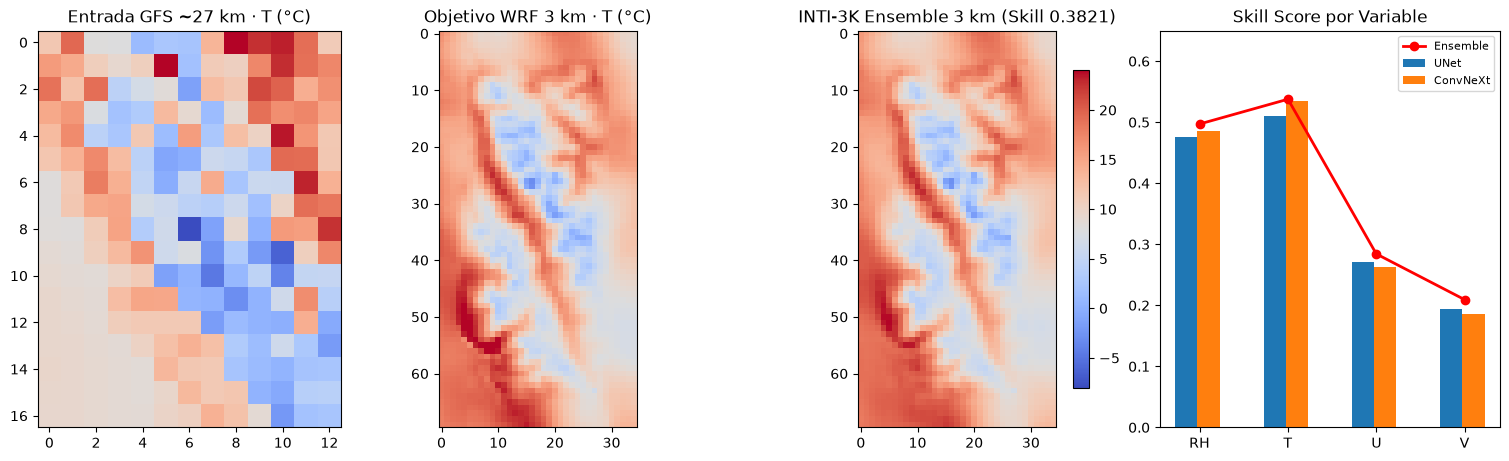

In [6]:
BLEND_WEIGHTS = np.array([
    [0.25, 0.20, 0.40, 0.40],  # PhysicsUNet
    [0.30, 0.80, 0.35, 0.30],  # PhysicsConvNeXt
    [0.45, 0.00, 0.25, 0.30],  # PhysicsFNO
], dtype=np.float32)

ensemble = EnsembleDownscaler(
    grid=grid_t, topo_features=topo_t, lapse_delta_norm=lapse_delta_t, blend_weights=BLEND_WEIGHTS
).to(device)
ensemble.unet.load_state_dict({k: v.to(device) for k, v in state_unet.items()})
ensemble.convnext.load_state_dict({k: v.to(device) for k, v in state_conv.items()})
ensemble.fno.load_state_dict({k: v.to(device) for k, v in state_fno.items()})
ensemble.eval()

val_oof_ens = predict_with_model(ensemble, Wtr_n[val_mask], M24_tr_n[val_mask], Td_tr_n[val_mask], h_tr[val_mask])
sc_ens, rmse_ens, skill_ens = evaluate_skill_score(val_oof_ens, Ytr[val_mask])

t_inf0 = time.time()
_ = predict_with_model(ensemble, Wte_n[:24], M24_te_n[:24], Td_te_n[:24], h_te[:24], bs=24)
inf_24h_ms = (time.time() - t_inf0) * 1000.0

print("=" * 75)
print(f"ENSEMBLE UNIFICADO (INTI-3K) -> Skill Score Val: {sc_ens:.4f}")
print(f"  Skill por variable : {skill_ens}")
print(f"  RMSE por variable  : {rmse_ens}")
print(f"  Inferencia 24h     : {inf_24h_ms:.1f} ms en {device.upper()}")
print("=" * 75)

# Visualización comparativa: GFS 27 km vs WRF 3 km Real vs INTI-3K Ensemble 3 km
sample_idx = min(18, len(val_oof_ens) - 1)
val_raw_X = Xtr[val_mask][sample_idx]
val_true_Y = Ytr[val_mask][sample_idx]
val_pred_Y = val_oof_ens[sample_idx]

fig, axes = plt.subplots(1, 4, figsize=(15, 4.5), constrained_layout=True)
axes[0].imshow(val_raw_X[..., 1] - 273.15, cmap="coolwarm")
axes[0].set_title("Entrada GFS ~27 km · T (°C)")
im1 = axes[1].imshow(np.flipud(val_true_Y[..., 1]) - 273.15, cmap="coolwarm", vmin=-8, vmax=24)
axes[1].set_title("Objetivo WRF 3 km · T (°C)")
axes[2].imshow(np.flipud(val_pred_Y[..., 1]) - 273.15, cmap="coolwarm", vmin=-8, vmax=24)
axes[2].set_title(f"INTI-3K Ensemble 3 km (Skill {sc_ens:.4f})")
plt.colorbar(im1, ax=axes[2], shrink=0.8)

x_pos = np.arange(len(VARS))
axes[3].bar(x_pos - 0.15, [evaluate_skill_score(oof_unet, Ytr[val_mask])[2][v] for v in VARS], 0.25, label="UNet")
axes[3].bar(x_pos + 0.10, [evaluate_skill_score(oof_conv, Ytr[val_mask])[2][v] for v in VARS], 0.25, label="ConvNeXt")
axes[3].plot(x_pos, [skill_ens[v] for v in VARS], "ro-", linewidth=2, label="Ensemble")
axes[3].set_xticks(x_pos); axes[3].set_xticklabels(VARS)
axes[3].set_ylim(0, 0.65); axes[3].set_title("Skill Score por Variable")
axes[3].legend(fontsize=8)
plt.show()


In [7]:
weights_path = MODELS_DIR / "modelo.pt"
torch.save({k: v.detach().cpu() for k, v in ensemble.state_dict().items()}, weights_path)
print(f"Pesos limpios guardados en {weights_path} ({weights_path.stat().st_size / 1e6:.2f} MB)")

np.savez_compressed(
    MODELS_DIR / "norm_stats.npz",
    mu_x=mu_x,
    sd_x=sd_x,
    mu_td=np.array(mu_td, dtype=np.float32),
    sd_td=np.array(sd_td, dtype=np.float32),
    clim_trn=clim_trn,
    anom_sd=anom_sd,
    clim_rmse_val=clim_rmse_val,
    val_rmse_per_var=np.array([rmse_ens[v] for v in VARS], dtype=np.float32),
    blend_weights=BLEND_WEIGHTS,
    arch=np.array("ensemble_3fam_v6"),
    width=np.array(64),
    best_score=np.array(sc_ens),
    exp_id=np.array("ensemble_3fam_notebook"),
)

# Inferencia sobre test.npz y generación de submission.csv
test_preds = predict_with_model(ensemble, Wte_n, M24_te_n, Td_te_n, h_te)
sample = pd.read_csv(find("sample_submission.csv"))
pos = {k: i for i, k in enumerate(tte)}
parts = sample["id"].str.split("_", expand=True)
ti = parts[0].map(pos).values
r = parts[1].astype(int).values
c = parts[2].astype(int).values

sub = pd.DataFrame({"id": sample["id"]})
for k, v in enumerate(VARS):
    sub[v] = test_preds[ti, r, c, k].round(3)

sub_path = ROOT_DIR / "submission.csv"
sub.to_csv(sub_path, index=False)

assert sub.shape == sample.shape, f"Shape mismatch: {sub.shape} vs {sample.shape}"
assert list(sub.columns) == list(sample.columns)
assert int(sub.isna().sum().sum()) == 0, "NaNs detectados"
assert (sub["id"].values == sample["id"].values).all(), "IDs desalineados"

print(f"submission.csv verificado y guardado en {sub_path}: shape={sub.shape}")
sub.head()


Pesos limpios guardados en C:\Users\Acer\Desktop\Estudio\Proyectos\IA_PUCP\models\modelo.pt (30.70 MB)


submission.csv verificado y guardado en C:\Users\Acer\Desktop\Estudio\Proyectos\IA_PUCP\submission.csv: shape=(646800, 5)


,id,RH,T,U,V
0,2024070200_00_00,89.495003,290.046997,-0.407,3.591
1,2024070200_00_01,89.389000,289.532990,-0.156,2.989
2,2024070200_00_02,84.531998,289.329010,0.244,2.665
3,2024070200_00_03,81.046997,289.345001,0.581,2.291
4,2024070200_00_04,80.945000,289.507996,0.748,1.997
